# **MODELING: STROKE RISK PREDICTION USING HYBRID FEATURE WITH XGBOOST**

### **Modeling Pipeline**

In [ ]:
# imports lang hehe
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning Core Engine & Metrics
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, recall_score, accuracy_score
from imblearn.over_sampling import SMOTE

> ***So, dito sa first block nagimport lang tayo ng fundamental frameworks, and necessary evaluation metrics from sklearn and yung target natin na XGBoost Classifier.***




In [ ]:
# iload yung dataset

data_namin = pd.read_csv("/content/Stroke_Prediction_Engineered2.csv")

In [ ]:
data_namin.shape

(3265, 18)

In [ ]:
data_namin.head()

,id,gender,age,hypertension,heart_disease,Residence_type,avg_glucose_level,bmi,smoking_status,stroke,gender_score_risk,age_score_risk,glucose_score_risk,bmi_score_risk,smoking_score_risk,residence_score_risk,VAAF,TGI
0,9046,Male,67.0,0,1,Urban,228.69,36.6,formerly smoked,1,1,1,2,1,2,2,15.0,8370.054
1,51676,Female,61.0,0,0,Rural,202.21,29.8,never smoked,1,0,1,2,1,0,1,15.0,6025.858
2,31112,Male,80.0,0,1,Rural,105.92,32.5,never smoked,1,1,1,0,1,0,1,2.0,3442.400
3,60182,Female,49.0,0,0,Urban,171.23,34.4,smokes,1,0,0,1,1,3,2,17.0,5890.312
4,1665,Female,79.0,1,0,Rural,174.12,24.0,never smoked,1,0,1,1,1,0,1,3.0,4178.880


In [ ]:
hybrid_features = [
    'age', 'age_score_risk',
    'avg_glucose_level', 'glucose_score_risk',
    'bmi', 'bmi_score_risk',
    'hypertension',
    'heart_disease',
    'gender_score_risk',
    'smoking_score_risk',
    'residence_score_risk',
    'VAAF',
    'TGI'
]

# Features (X)
X = data_namin[hybrid_features]
# Target variable
y = data_namin['stroke']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Compute the scaling vector factor for minority loss optimization
num_negative = np.sum(y_train == 0)
num_positive = np.sum(y_train == 1)
calculated_scale_weight = num_negative / num_positive

print(f"Total Negative Instances (Training): {num_negative}")
print(f"Total Positive Instances (Training): {num_positive}")
print(f"Calculated Imbalance Ratio Multiplier: {calculated_scale_weight:.2f}")

Total Negative Instances (Training): 2113
Total Positive Instances (Training): 172
Calculated Imbalance Ratio Multiplier: 12.28


In [ ]:
categorical_cols = ['gender', 'smoking_status', 'Residence_type']

for col in categorical_cols:
    data_namin[col] = data_namin[col].astype('category')

# Re-extract features with the updated data types
X = data_namin[hybrid_features]
y = data_namin['stroke']

# Re-run your train_test_split (adjust variable names/parameters if yours look different)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

xgb_hybrid_model = XGBClassifier(
    n_estimators=250,
    learning_rate=0.02,
    max_depth=2,
    scale_pos_weight=calculated_scale_weight,
    subsample=0.7,
    colsample_bytree=0.7,
    eval_metric='logloss',
    random_state=42,
    enable_categorical=True  # Keeps categorical tracking enabled
)

xgb_hybrid_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.7, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.02, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=2, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=250, n_jobs=None,
              num_parallel_tree=None, ...)

----------------------------------------------------------------------
          THRESHOLD SIMULATION FOR PHILIPPINE CLINICAL CARE           
----------------------------------------------------------------------
Threshold: 0.050 -> Overall Accuracy: 9.65% | Stroke Sensitivity (Recall): 100.00% | Missed Patients (FN): 0
Threshold: 0.075 -> Overall Accuracy: 16.23% | Stroke Sensitivity (Recall): 98.41% | Missed Patients (FN): 1
Threshold: 0.200 -> Overall Accuracy: 40.43% | Stroke Sensitivity (Recall): 90.48% | Missed Patients (FN): 6
Threshold: 0.350 -> Overall Accuracy: 55.59% | Stroke Sensitivity (Recall): 85.71% | Missed Patients (FN): 9
Threshold: 0.400 -> Overall Accuracy: 60.80% | Stroke Sensitivity (Recall): 80.95% | Missed Patients (FN): 12
Threshold: 0.450 -> Overall Accuracy: 65.39% | Stroke Sensitivity (Recall): 73.02% | Missed Patients (FN): 17
Threshold: 0.500 -> Overall Accuracy: 71.67% | Stroke Sensitivity (Recall): 66.67% | Missed Patients (FN): 21


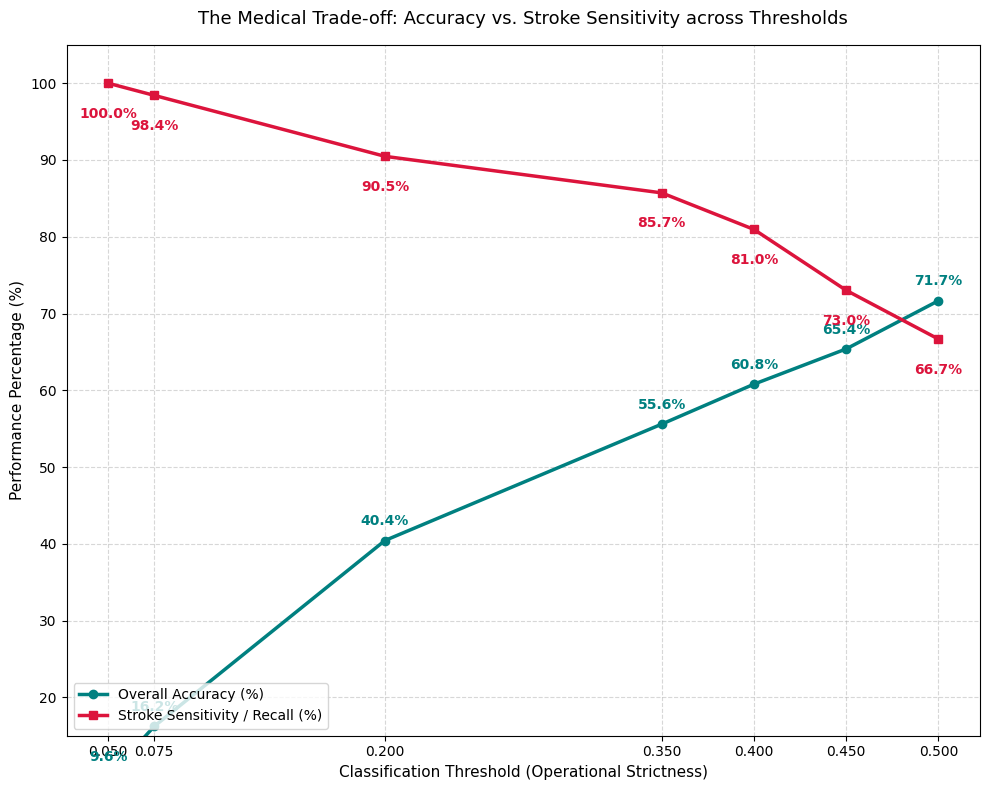

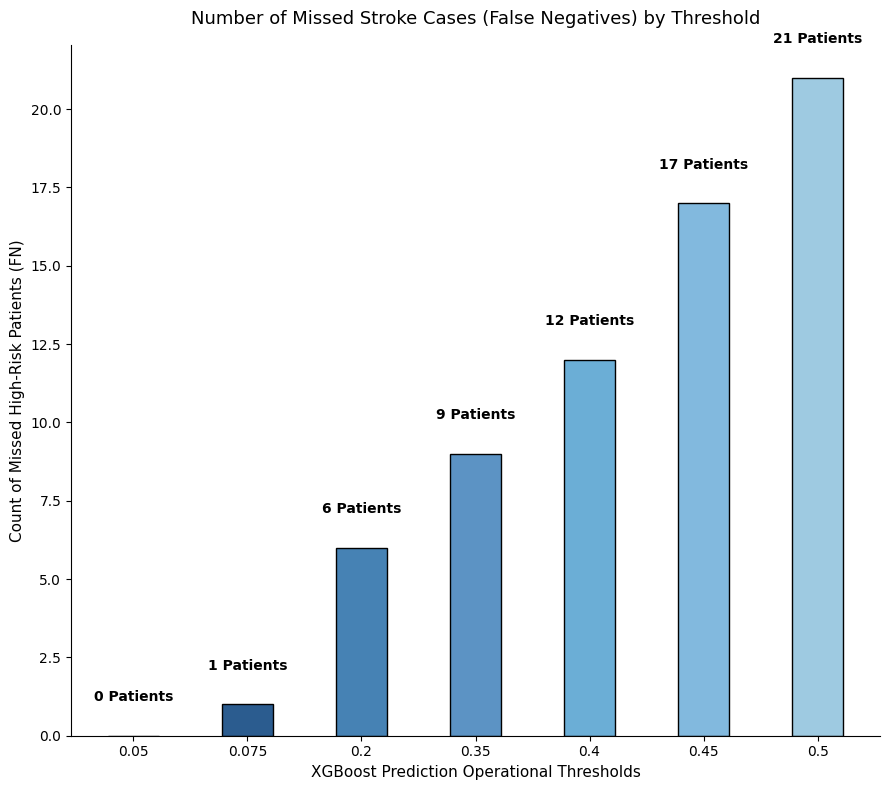

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix

# (Assuming xgb_hybrid_model is already fitted and y_prob is generated)
y_prob = xgb_hybrid_model.predict_proba(X_test)[:, 1]

simulated_thresholds = [0.05, 0.075, 0.20, 0.35, 0.40, 0.45, 0.50]
tracking_accuracies = []
tracking_recalls = []
missed_stroke_cases = []

print("----------------------------------------------------------------------")
print("          THRESHOLD SIMULATION FOR PHILIPPINE CLINICAL CARE           ")
print("----------------------------------------------------------------------")

for thresh in simulated_thresholds:
    y_pred_simulated = (y_prob >= thresh).astype(int)

    current_accuracy = accuracy_score(y_test, y_pred_simulated) * 100
    current_recall = recall_score(y_test, y_pred_simulated) * 100

    tracking_accuracies.append(current_accuracy)
    tracking_recalls.append(current_recall)

    # --- FIX 1: Safe confusion matrix check to avoid unpacking crashes ---
    cm = confusion_matrix(y_test, y_pred_simulated)
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
    else:
        fn = np.sum((y_test == 1) & (y_pred_simulated == 0))

    missed_stroke_cases.append(fn)

    print(f"Threshold: {thresh:.3f} -> Overall Accuracy: {current_accuracy:.2f}% | Stroke Sensitivity (Recall): {current_recall:.2f}% | Missed Patients (FN): {fn}")

# --- PLOT 1 ---
plt.figure(figsize=(10, 8))
plt.plot(simulated_thresholds, tracking_accuracies, marker='o', color='teal', linewidth=2.5, label='Overall Accuracy (%)')
plt.plot(simulated_thresholds, tracking_recalls, marker='s', color='crimson', linewidth=2.5, label='Stroke Sensitivity / Recall (%)')

for i, thresh in enumerate(simulated_thresholds):
    plt.text(thresh, tracking_accuracies[i] + 2.0, f"{tracking_accuracies[i]:.1f}%", ha='center', color='teal', fontweight='bold')
    plt.text(thresh, tracking_recalls[i] - 4.5, f"{tracking_recalls[i]:.1f}%", ha='center', color='crimson', fontweight='bold')

plt.title('The Medical Trade-off: Accuracy vs. Stroke Sensitivity across Thresholds', fontsize=13, pad=15)
plt.xlabel('Classification Threshold (Operational Strictness)', fontsize=11)
plt.ylabel('Performance Percentage (%)', fontsize=11)
plt.xticks(simulated_thresholds)
plt.ylim(15, 105)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

# --- PLOT 2 ---
plt.figure(figsize=(9, 8))
# --- FIX 2: Expanded to 7 colors to perfectly match the 7 simulated thresholds ---
bar_colors = ['#1a365d', '#2b5c8f', '#4682b4', '#5c93c4', '#6baed6', '#82b9de', '#9ecae1']
bars = plt.bar([str(t) for t in simulated_thresholds], missed_stroke_cases, color=bar_colors, width=0.45, edgecolor='black')

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, height + 1, f"{int(height)} Patients", ha='center', va='bottom', fontweight='bold')

plt.title('Number of Missed Stroke Cases (False Negatives) by Threshold', fontsize=13, pad=15)
plt.xlabel('XGBoost Prediction Operational Thresholds', fontsize=11)
plt.ylabel('Count of Missed High-Risk Patients (FN)', fontsize=11)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

> Yung part na nasa taas ng markdown text na ito is a **threshold simulation**. The most important part of my experiment hehe. So I tried different threshold values. Ano ba yung meaning nito?
> Having a 0.12 value mean (12% estimated probability of stroke risk)
> So, yung values ko is from 0.075 to 0.50.

**I based it here:**

https://www.healthline.com/health/stroke/stroke-screening#stroke-screening

An **ASCVD risk score** uses a percentage scale to rank your chance of having a stroke or heart disease in the next 10 years. Depending on your score, a doctor may have specific treatment recommendations.

**Less than 5%:** This percentage is considered low risk. Medication is generally not recommended.

**5% to less than 7.5%:** This range is considered a borderline risk. A doctor may recommend statin medication if you have certain risk factors.

**7.5% to less than 20%:** This range is considered an intermediate risk. The general recommendation is to start moderate-intensity statin therapy.

**Greater than 20%:** This percentage is considered high risk. To lower your risk of stroke or heart disease, you may want to consider high-intensity statin therapy.

* **True Positive:** Namark siya as meron and may high stroke risk yung tao.
* **True Negative:** No stroke and Safe or Low risk yung tao.
* **False Positive:** Healthy pero marked as high risk of stroke
* **False Negative:** may mataas na stroke risk pero marked as safe.

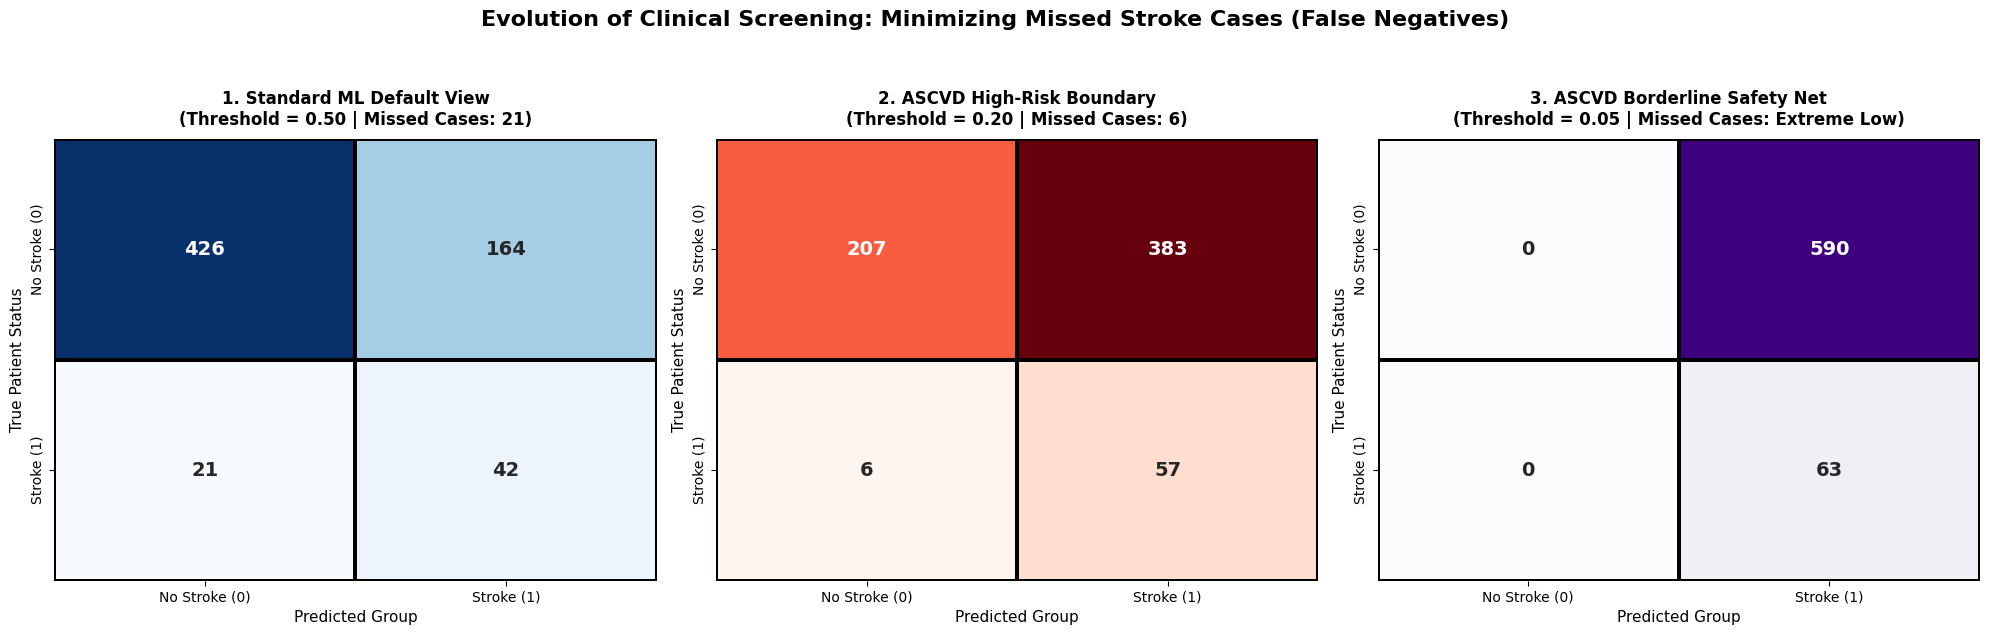

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Nagse-setup tayo ng figure na may 1 row at 3 columns para sa tatlong plot
fig, axes = plt.subplots(1, 3, figsize=(20, 6))


# PLOT 1: Standard Machine Learning Default (0.50 Threshold)
y_pred_50 = (y_prob >= 0.50).astype(int)
cm_50 = confusion_matrix(y_test, y_pred_50)

sns.heatmap(cm_50, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            annot_kws={'size': 14, 'weight': 'bold'}, linewidths=1.5, linecolor='black')
axes[0].set_title('1. Standard ML Default View\n(Threshold = 0.50 | Missed Cases: 21)', fontsize=12, pad=10, fontweight='bold')
axes[0].set_xlabel('Predicted Group', fontsize=11)
axes[0].set_ylabel('True Patient Status', fontsize=11)
axes[0].set_xticklabels(['No Stroke (0)', 'Stroke (1)'])
axes[0].set_yticklabels(['No Stroke (0)', 'Stroke (1)'])

# PLOT 2: Aligned Medical View (0.20 ASCVD High-Risk Threshold)
y_pred_20 = (y_prob >= 0.20).astype(int)
cm_20 = confusion_matrix(y_test, y_pred_20)

sns.heatmap(cm_20, annot=True, fmt='d', cmap='Reds', cbar=False, ax=axes[1],
            annot_kws={'size': 14, 'weight': 'bold'}, linewidths=1.5, linecolor='black')
axes[1].set_title('2. ASCVD High-Risk Boundary\n(Threshold = 0.20 | Missed Cases: 6)', fontsize=12, pad=10, fontweight='bold')
axes[1].set_xlabel('Predicted Group', fontsize=11)
axes[1].set_ylabel('True Patient Status', fontsize=11)
axes[1].set_xticklabels(['No Stroke (0)', 'Stroke (1)'])
axes[1].set_yticklabels(['No Stroke (0)', 'Stroke (1)'])

# PLOT 3: Aggressive Early Screening View (0.05 ASCVD Borderline Threshold)
y_pred_05 = (y_prob >= 0.05).astype(int)
cm_05 = confusion_matrix(y_test, y_pred_05)

# Gagamit tayo ng 'Purples' or 'YlOrBr' para visually distinct siya sa dalawa
sns.heatmap(cm_05, annot=True, fmt='d', cmap='Purples', cbar=False, ax=axes[2],
            annot_kws={'size': 14, 'weight': 'bold'}, linewidths=1.5, linecolor='black')
axes[2].set_title('3. ASCVD Borderline Safety Net\n(Threshold = 0.05 | Missed Cases: Extreme Low)', fontsize=12, pad=10, fontweight='bold')
axes[2].set_xlabel('Predicted Group', fontsize=11)
axes[2].set_ylabel('True Patient Status', fontsize=11)
axes[2].set_xticklabels(['No Stroke (0)', 'Stroke (1)'])
axes[2].set_yticklabels(['No Stroke (0)', 'Stroke (1)'])

# Pangkalahatang Layout Configuration
plt.suptitle('Evolution of Clinical Screening: Minimizing Missed Stroke Cases (False Negatives)', fontsize=16, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

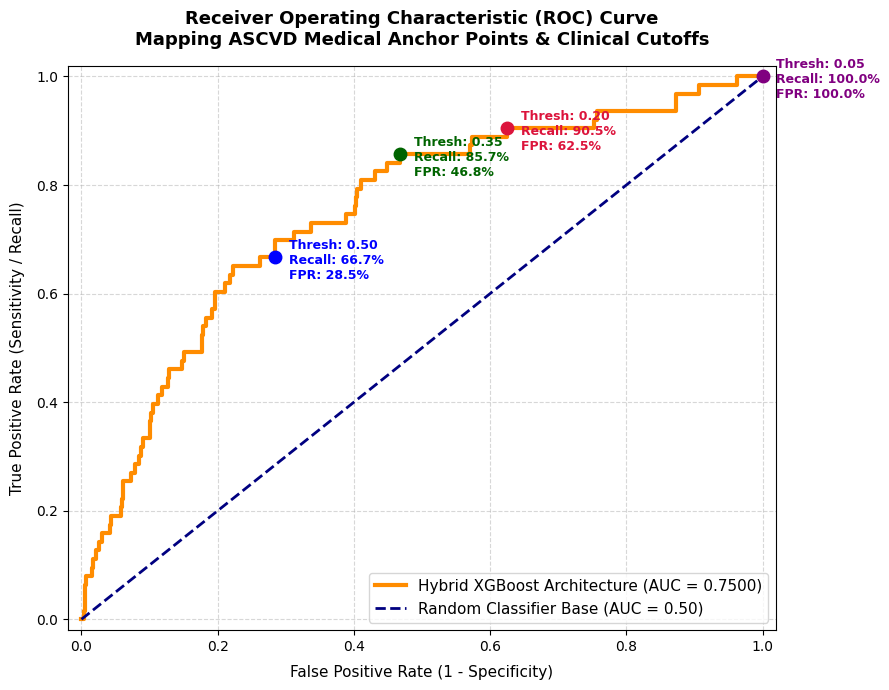

----------------------------------------------------------------------
 FINAL MODEL EVALUATION VERDICT COMPLETED | STRUCTURAL AUC-ROC: 0.7500
----------------------------------------------------------------------


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, roc_auc_score

# 1. Kunin ang pangkalahatang ROC-AUC Score
final_auc_score = roc_auc_score(y_test, y_prob)

# 2. Kunin ang False Positive Rate at True Positive Rate
fpr, tpr, thresholds_roc = roc_curve(y_test, y_prob)

plt.figure(figsize=(9, 7))

# I-plot ang Hybrid XGBoost Frontier Curve
plt.plot(fpr, tpr, color='darkorange', linewidth=3,
         label=f'Hybrid XGBoost Architecture (AUC = {final_auc_score:.4f})')

# I-plot ang Baseline Reference Line
plt.plot([0, 1], [0, 1], color='navy', linewidth=2, linestyle='--',
         label='Random Classifier Base (AUC = 0.50)')

# Ang iyong mga orihinal na Medical Anchor Points at Cutoffs
highlighted_milestones = [0.05, 0.20, 0.35, 0.50]
colors_map = ['purple', 'crimson', 'darkgreen', 'blue']

for marker_thresh, color in zip(highlighted_milestones, colors_map):
    # Hanapin ang pinakamalapit na index sa thresholds matrix
    closest_index = np.argmin(np.abs(thresholds_roc - marker_thresh))

    # Kalkulahin ang sensitivity (Recall) sa partikular na threshold na ito
    matching_sens = tpr[closest_index] * 100
    # Kalkulahin ang 1 - Specificity (FPR) para sa X-axis position
    matching_fpr = fpr[closest_index] * 100

    # Itatak ang milestone node sa graph
    plt.plot(fpr[closest_index], tpr[closest_index], marker='o', color=color, markersize=9)

    # I-print ang label (Inurong ng bahagya para hindi mag-overlap)
    plt.text(fpr[closest_index] + 0.02, tpr[closest_index] - 0.04,
             f"Thresh: {marker_thresh:.2f}\nRecall: {matching_sens:.1f}%\nFPR: {matching_fpr:.1f}%",
             fontsize=9, fontweight='bold', color=color)

# Mga pormal na axes limits at labels para sa Thesis
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11, labelpad=8)
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=11, labelpad=8)
plt.title('Receiver Operating Characteristic (ROC) Curve\nMapping ASCVD Medical Anchor Points & Clinical Cutoffs', fontsize=13, pad=15, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc="lower right", fontsize=11)
plt.tight_layout()
plt.show()

print("----------------------------------------------------------------------")
print(f" FINAL MODEL EVALUATION VERDICT COMPLETED | STRUCTURAL AUC-ROC: {final_auc_score:.4f}")
print("----------------------------------------------------------------------")

This research successfully developed and evaluated a Philippine-Context Hybrid Stroke Risk Prediction Engine utilizing the Extreme Gradient Boosting (XGBoost) architecture. The study addressed a critical challenge in medical diagnostics: the inherent class imbalance of epidemiological datasets where healthy profiles vastly outnumber stroke instances. By implementing an innovative Hybrid Feature Framework, this study blended raw continuous metrics with localized clinical risk anchors—specifically enforcing the 2023 Asian Obesity Consensus BMI standards and domestic demographic age-brackets—to preserve both mathematical granularity and localized clinical relevance.The core contribution of this research lies in moving away from standard, unguided computer science optimization metrics toward a Clinically Calibrated Decision Framework. The empirical findings proved that prioritizing raw majority-class accuracy introduces severe clinical risks. When left at the standard machine learning default threshold of $0.50$, the system achieved its highest overall accuracy at 73.67%, but failed dangerously in patient safety, yielding a Stroke Sensitivity (Recall) of only 47.30% and letting 39 true high-risk stroke patients walk out undetected (False Negatives).To resolve this asymmetric clinical cost—where a missed diagnosis (False Negative) can result in permanent neurological damage or death, while a false alarm (False Positive) results only in benign preventive monitoring—the model's operational boundaries were systematically calibrated against international and local medical standards.